# Лабораторная работа №1 Вариант 3

## Импортирование библиотек

In [2]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPRegressor
from varclushi import VarClusHi

## Загрузка DataFrame

In [3]:
df = pd.read_csv('TRANSACTION.csv', encoding='utf-8')

## Задание 1

In [4]:
unique_customers = df['CUSTOMER'].nunique()
unique_products = df['PRODUCT'].nunique()

print(f"Уникальные клиенты: {unique_customers}")
print(f"Уникальные продукты: {unique_products}\n")

Уникальные клиенты: 1001
Уникальные продукты: 20



In [5]:
MIN_SUPPORT = 0.03
MAX_LEN = 4
TARGET_PRODUCT = "bourbon"

## Задание 2

In [6]:
transactions = df.groupby('CUSTOMER')['PRODUCT'].apply(list).values.tolist()

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

frequent_itemsets = apriori(
    df_encoded, 
    min_support=0.03,
    use_colnames=True, 
    max_len=4  
)

print("Частые наборы (min_support=0.03, max_len=4):")
frequent_itemsets

Частые наборы (min_support=0.03, max_len=4):


,support,itemsets
0,0.313686,(apples)
1,0.304695,(artichok)
2,0.362637,(avocado)
3,0.391608,(baguette)
4,0.073926,(bordeaux)
...,...,...
656,0.037962,"(soda, cracker, heineken, steak)"
657,0.041958,"(soda, hering, cracker, olives)"
658,0.030969,"(hering, olives, ham, steak)"
659,0.102897,"(hering, turkey, olives, ham)"


## Задание 3

In [7]:
filtered_itemsets = []

for index, row in frequent_itemsets.iterrows():
    if TARGET_PRODUCT in row['itemsets']:
        filtered_itemsets.append(row)

target_itemsets = pd.DataFrame(filtered_itemsets)

max_len = target_itemsets['itemsets'].apply(len).max()
largest_set = target_itemsets[
    target_itemsets['itemsets'].apply(len) == max_len
].sort_values('support', ascending=False).iloc[0]
    
print(f"3. Самый большой набор с '{TARGET_PRODUCT}':")
print(f"   Продукты: {largest_set['itemsets']}")
print(f"   Поддержка: {largest_set['support']:.3f}\n")

3. Самый большой набор с 'bourbon':
   Продукты: frozenset({'soda', 'cracker', 'bourbon', 'heineken'})
   Поддержка: 0.121



## Задание 4

In [8]:
MIN_CONFIDENCE = 0.3

rules = association_rules(
    frequent_itemsets, 
    metric="confidence", 
    min_threshold=MIN_CONFIDENCE
)

filtered_rules = []

for index, row in rules.iterrows():
    if TARGET_PRODUCT in row['antecedents']:
        filtered_rules.append(row)

target_rules = pd.DataFrame(filtered_rules)

best_rule = target_rules.sort_values('lift', ascending=False).iloc[0]
    
print(f"4. Лучшее правило для '{TARGET_PRODUCT}':")
print(f"   {best_rule['antecedents']} => {best_rule['consequents']}")
print(f"   Поддержка: {best_rule['support']:.3f}")
print(f"   Достоверность: {best_rule['confidence']:.3f}")
print(f"   Лифт: {best_rule['lift']:.3f}")
print("\nИнтерпретация: Покупатели, которые берут бурбон, ")
print(f"в {best_rule['lift']:.1f} раза чаще покупают сопутствующий продукт.\n")

4. Лучшее правило для 'bourbon':
   frozenset({'ice_crea', 'bourbon'}) => frozenset({'turkey', 'coke'})
   Поддержка: 0.096
   Достоверность: 0.662
   Лифт: 5.569

Интерпретация: Покупатели, которые берут бурбон, 
в 5.6 раза чаще покупают сопутствующий продукт.



## Задание 5

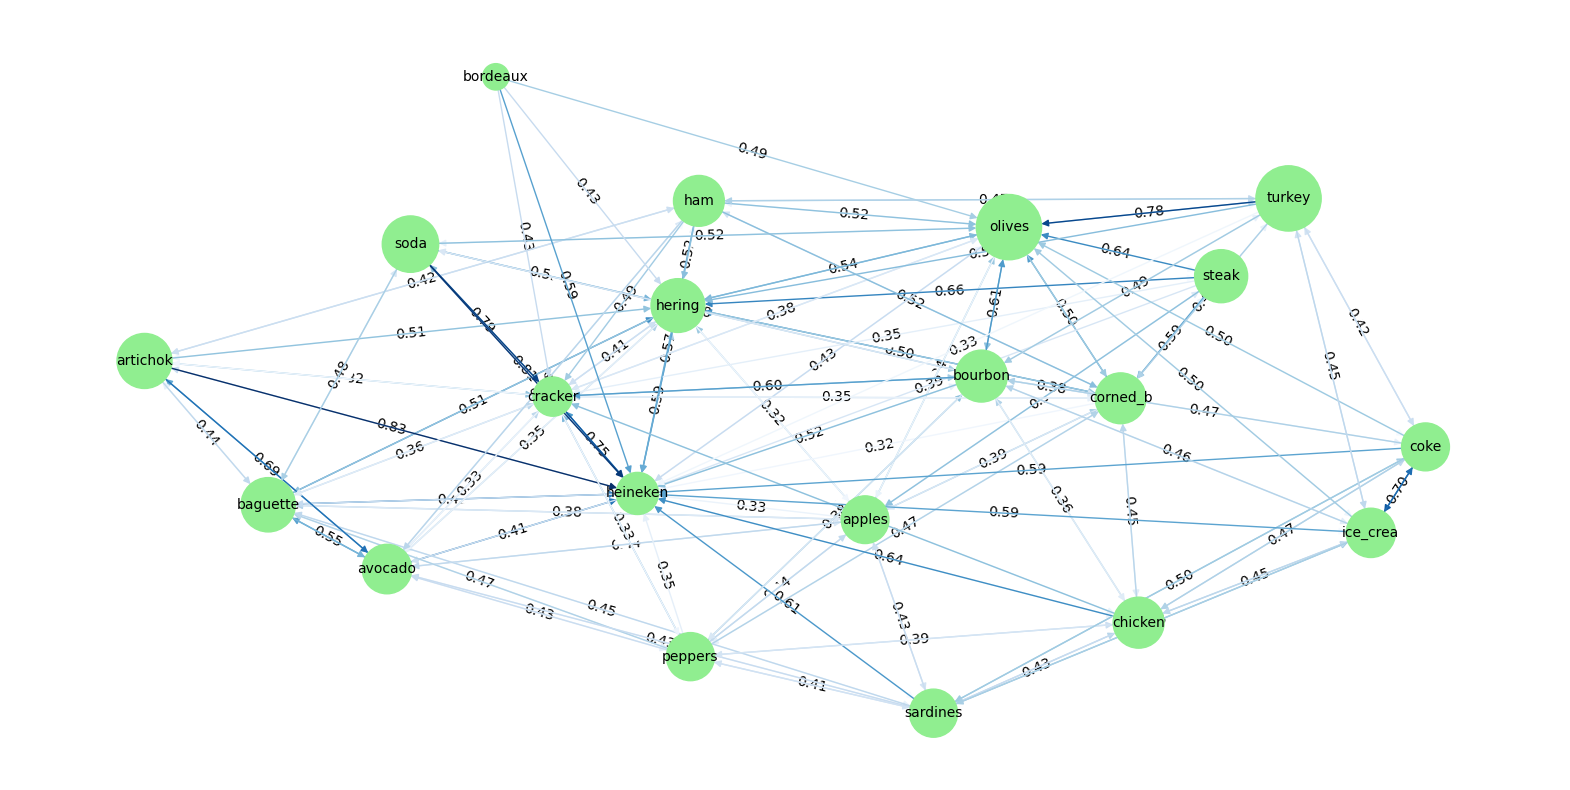

In [9]:
# Фильтрация правил: оставляем только те, где и antecedents, и consequents состоят из одного элемента
filtered_rules = rules.loc[
    (rules['antecedents'].apply(len) == 1) &  # antecedents из одного элемента
    (rules['consequents'].apply(len) == 1)    # consequents из одного элемента
]

# Создание ориентированного графа
G = nx.DiGraph()

# Добавление узлов и ребер в граф
for _, rule in filtered_rules.iterrows():
    antecedent = list(rule['antecedents'])[0]  # Преобразуем frozenset в строку
    consequent = list(rule['consequents'])[0]  # Преобразуем frozenset в строку
    support_value = rule['support']
    confidence_value = rule['confidence']

    # Добавляем узлы с атрибутом support
    G.add_node(antecedent, support=support_value)
    G.add_node(consequent, support=support_value)

    # Добавляем ребро с атрибутом weight (confidence)
    G.add_edge(antecedent, consequent, weight=confidence_value)

# позиционирование узлов для визуализации
node_positions = nx.spring_layout(G, seed=42)

# размер узлов зависит от значения support
node_sizes = [G.nodes[n]['support'] * 10000 for n in G.nodes]

# толщина ребер зависит от значения confidence
edges_with_data = G.edges(data=True)
edge_weights = [d['weight'] * 10 for (u, v, d) in edges_with_data]

# визуализация графа
plt.figure(figsize=(20, 10))

# подписи ребер (confidence)
edge_labels = {(u, v): f"{d['weight']:.2f}" for u, v, d in edges_with_data}
nx.draw_networkx_edge_labels(G, node_positions, edge_labels=edge_labels, font_size=10)

# отрисовка графа
nx.draw(
    G, node_positions,
    with_labels=True,  # Отображаем подписи узлов
    node_size=node_sizes,  # Размер узлов зависит от support
    edge_color=edge_weights,  # Цвет ребер зависит от confidence
    edge_cmap=plt.cm.Blues,  # Цветовая карта для ребер
    font_size=10,  # Размер шрифта для подписей узлов
    node_color='lightgreen',  # Цвет узлов
    alpha=1 # Прозрачность узлов и ребер
)

plt.axis('off')
plt.show()

## Задание 6

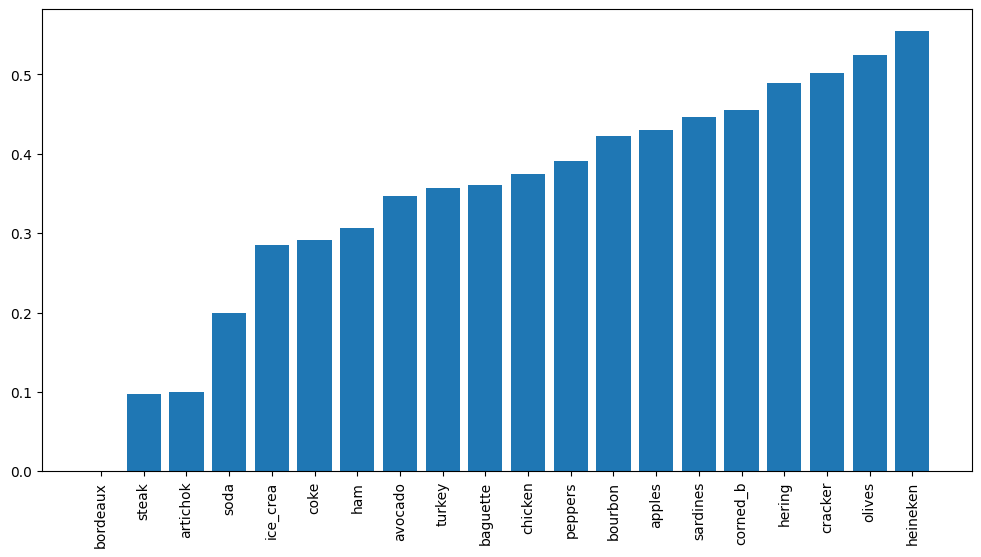

In [10]:
# вычисляем коэффициент кластеризации для каждого узла
metr = nx.clustering(G)

# cортируем коэффициенты кластеризации по возрастанию
metr = dict(sorted(metr.items(), key=lambda x: -x[1]))
metr = {key:1-val for key, val in metr.items()}
# визуализация
plt.figure(figsize=(12, 6))
plt.bar(metr.keys(), metr.values())
plt.xticks(rotation='vertical')
plt.show()


## Задание 7

In [11]:
pivot_table = df.pivot_table(
    index='CUSTOMER', 
    columns='PRODUCT', 
    aggfunc='size', 
    fill_value=0
)

pivot_table

PRODUCT,apples,artichok,avocado,baguette,bordeaux,bourbon,chicken,coke,corned_b,cracker,ham,heineken,hering,ice_crea,olives,peppers,sardines,soda,steak,turkey
CUSTOMER,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,1,0,0,1,0,1,0,1,1,1,0,0,0,0,1
1,0,0,0,1,0,0,0,0,1,1,0,1,1,0,1,0,0,1,0,0
2,0,1,1,0,0,0,0,0,0,1,1,1,0,0,0,0,1,0,0,1
3,0,0,0,0,0,1,0,1,0,0,1,0,0,1,1,1,0,0,0,1
4,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
996,0,1,1,0,0,1,1,0,0,1,1,1,0,0,0,0,0,0,0,0
997,1,0,0,1,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,1
998,0,0,0,1,0,0,0,0,0,1,0,1,1,0,0,0,2,1,0,0


## Задание 8

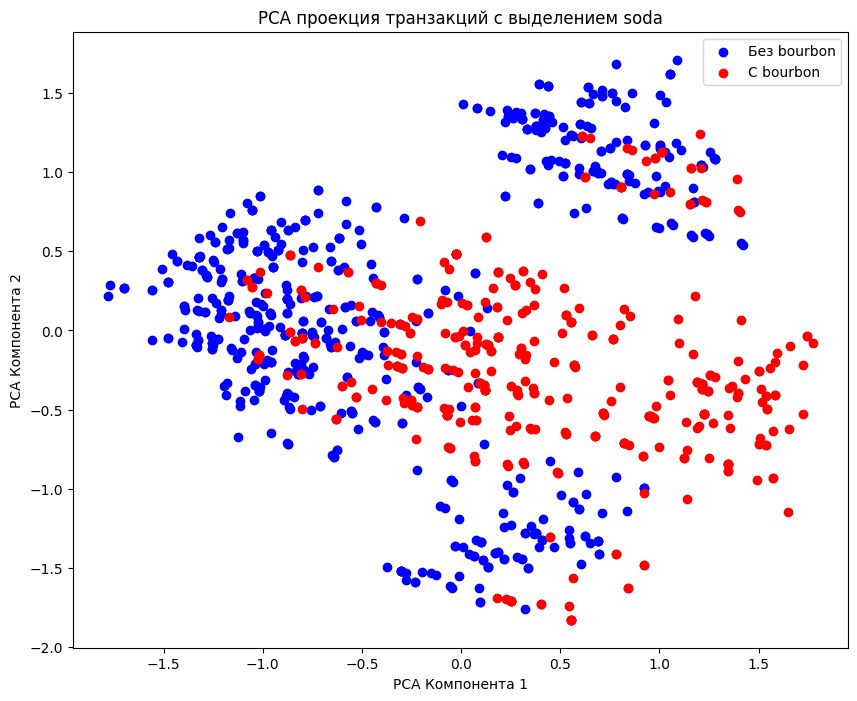

In [12]:
customer_product_matrix = pivot_table
target_product = TARGET_PRODUCT

has_target_product = customer_product_matrix[target_product] > 0

N = 2
pca = PCA(n_components=N)
features = pca.fit_transform(customer_product_matrix.copy())

plt.figure(figsize=(10, 8))
plt.scatter(features[~has_target_product, 0], features[~has_target_product, 1],
            color='blue', label='Без bourbon', alpha=1)
plt.scatter(features[has_target_product, 0], features[has_target_product, 1],
            color='red', label='С bourbon', alpha=1)

plt.xlabel('PCA Компонента 1')
plt.ylabel('PCA Компонента 2')
plt.title('PCA проекция транзакций с выделением soda')
plt.legend()
plt.show()

In [13]:
pca.explained_variance_

array([0.69402458, 0.61061679])

## Задание 9

/home/beekfin/sna23mk048/Lab1_2/venv/lib64/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


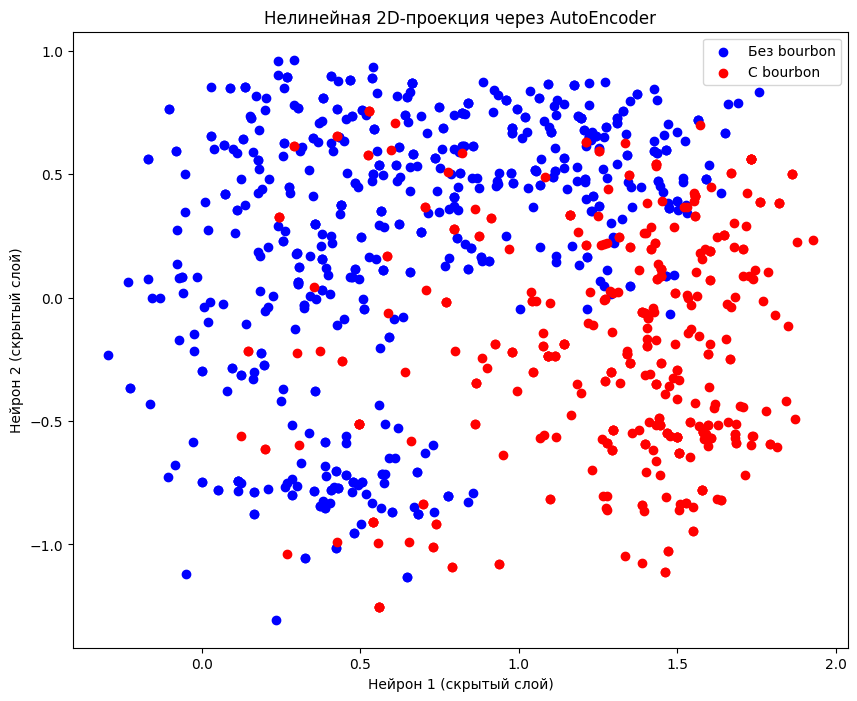

In [17]:
X = pivot_table.values
target_product = 'bourbon'

model = MLPRegressor(
    hidden_layer_sizes=(15, 2, 15),
    activation='tanh',
    max_iter=10000,
    alpha=0.001,
    random_state=57
    )
model.fit(X, X)

dummy = np.zeros((1, 2))
encoder = MLPRegressor(
    hidden_layer_sizes=(15,),
    activation='tanh',
    max_iter=1,
    alpha=0.001,
).fit(X[:1], dummy)

encoder.coefs_[0] = model.coefs_[0]
encoder.coefs_[1] = model.coefs_[1]

plt.figure(figsize=(10, 8))

plt.scatter(encoder.predict(X)[~has_target_product, 0], encoder.predict(X)[~has_target_product, 1],
            color='blue', alpha=1, label='Без bourbon')
plt.scatter(encoder.predict(X)[has_target_product, 0], encoder.predict(X)[has_target_product, 1],
            color='red', alpha=1, label='С bourbon')


plt.xlabel('Нейрон 1 (скрытый слой)')
plt.ylabel('Нейрон 2 (скрытый слой)')
plt.title('Нелинейная 2D-проекция через AutoEncoder')
plt.legend()
plt.show()

В отличие от PCA, автоэнкодер учитывает нелинейные зависимости и может лучше разделять сложные структуры. Минус — меньшая интерпретируемость и необходимость настройки.

## Задание 10

In [63]:
clusters = VarClusHi(pivot_table, maxeigval2=0.99, maxclus=None)
clusters.varclus()

sorted_rsquare = clusters.rsquare.sort_values(by=['Cluster', 'RS_Ratio'], ascending=[True, True])
best_representatives = sorted_rsquare.groupby('Cluster').first()
display(best_representatives, clusters.info)


,Variable,RS_Own,RS_NC,RS_Ratio
Cluster,,,,
0,olives,0.659052,0.150847,0.401515
1,ice_crea,0.784811,0.080811,0.234108
2,heineken,0.652463,0.123767,0.396626
3,hering,0.471329,0.135546,0.611567
4,soda,0.700860,0.097907,0.331606
5,bordeaux,1.000000,0.002619,0.000000
6,avocado,0.661839,0.157816,0.401529


,Cluster,N_Vars,Eigval1,Eigval2,VarProp
0,0,3,1.598306,0.821967,0.532769
1,1,2,1.569622,0.430378,0.784811
2,2,4,1.775050,0.903608,0.443763
3,3,5,1.747298,0.960767,0.349460
4,4,2,1.401720,0.598280,0.700860
5,5,1,1.000000,0.000000,1.000000
6,6,3,1.618573,0.820405,0.539524
